In [1]:
import os
import random
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import optuna

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.models.mswt_lstm_wrapper import MSWT_LSTMModel
from src.eval.scorer import VolatilityScorer
from src.trainer.walk_forward import WalkForwardTrainer

warnings.filterwarnings("ignore")

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

OUT_PATH = PROJECT_ROOT / "data" / "processed"
RESULTS_PATH = PROJECT_ROOT / "results" / "MSWT_LSTM"
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

df_train = pd.read_parquet(OUT_PATH / "brent_train.parquet")
y_train = df_train["log_returns"].values.astype("float64")
rs_train = df_train["rs_daily"].values.astype("float64")

df_test = pd.read_parquet(OUT_PATH / "brent_test.parquet")
y_test = df_test["log_returns"].values.astype("float64")
rs_test = df_test["rs_daily"].values.astype("float64")

assert not np.isnan(y_train).any() and not np.isnan(rs_train).any()
assert not np.isnan(y_test).any() and not np.isnan(rs_test).any()

print("=" * 70)
print(f"Train: {len(y_train)} obs  ({df_train.index[0].date()} -> {df_train.index[-1].date()})")
print(f"Test:  {len(y_test)} obs  ({df_test.index[0].date()} -> {df_test.index[-1].date()})")
print("=" * 70)

Train: 2171 obs  (2014-01-03 -> 2022-11-03)
Test:  953 obs  (2022-11-07 -> 2026-08-21)


## Introducción

El pronóstico de la volatilidad del Brent presenta un desafío estructural: las series financieras combinan tendencias suaves de largo plazo con shocks abruptos de alta frecuencia. Los modelos de Deep Learning tradicionales, como las redes LSTM o GRU estándar, procesan la serie completa en un solo flujo temporal. En consecuencia, la alta varianza de los eventos extremos suele saturar las compuertas de la red, limitando su capacidad para aprender la dinámica suave subyacente. 

Para abordar esta limitación, se diseñó el modelo **MS-WT-LSTM** (Multi-Scale Wavelet Transform LSTM). La premisa fundamental del modelo consistió en que, al separar la serie de retornos en múltiples resoluciones mediante la Transformada Wavelet Discreta (DWT), los componentes de baja frecuencia (aproximaciones) se manifiestan como curvas suaves y predecibles, mientras que los componentes de alta frecuencia (detalles) concentran el ruido y los shocks agresivos. Al tratar cada frecuencia de forma independiente, el modelo evita que los eventos extremos contaminen el aprendizaje de la tendencia general.

## Arquitectura del Modelo MS-WT-LSTM

Como se observó en el diagrama de la arquitectura, el modelo se estructuró en cuatro bloques secuenciales diseñados para procesar la información desde su descomposición frecuencial hasta la predicción final de la varianza.

### Bloque de Descomposición Multi-Escala (DWT)

La serie de retornos $r_t$ ingresó al bloque de Transformada Wavelet Discreta (DWT) utilizando la función madre `db4`. Se aplicó una descomposición hasta un nivel $J$ (donde $J$ fue un hiperparámetro optimizable). Este proceso generó un componente de aproximación de baja frecuencia ($A_J$) y $J$ componentes de detalle de alta frecuencia ($D_J, D_{J-1}, \dots, D_1$). Para evitar la pérdida de resolución temporal, cada uno de los $J+1$ componentes fue reconstruido a su longitud original $N$, conformando el conjunto de entrada $\mathcal{X} = \{A_J, D_J, \dots, D_1\}$.

### Bloque de Extracción de Características (LSTMs Paralelas)

Cada uno de los $J+1$ componentes fue alimentado de forma independiente a una red LSTM. Este bloque actuó como un extractor de características especializado por frecuencia. Para un componente $k$ en un instante $t$, la LSTM procesó una ventana de contexto $W$ y emitió un estado oculto $h_{k,t}$:
$$
h_{k,t} = \text{LSTM}_k(\mathcal{X}_{k, t-W:t})
$$
El uso de LSTMs en paralelo evitó que la alta varianza de los componentes de detalle (ruido y shocks) interfiriera con el aprendizaje de la tendencia suave en la aproximación.

### Bloque de Compuerta Dinámica

Los estados ocultos $h_{k,t}$ de las $J+1$ LSTMs fueron concatenados en un único vector $z_t$. Este vector ingresó a la red de compuertas, compuesta por una red neuronal densa (MLP) con dos capas ocultas y activación ReLU. La capa final de la MLP aplicó una función Softmax para generar un vector de pesos $\alpha_t$:
$$
\alpha_t = \text{Softmax}\left( W_3 \cdot \text{ReLU}\left( W_2 \cdot \text{ReLU}(W_1 z_t + b_1) + b_2 \right) + b_3 \right)
$$
Los pesos $\alpha_{k,t}$ representaron la probabilidad de que la frecuencia $k$ fuera la más relevante en el instante $t$, garantizando que la suma de todos los pesos fuera igual a 1.

El uso de la función ReLU en las capas ocultas respondió a la necesidad de capturar interacciones no lineales entre las frecuencias. Esta elección evitó el desvanecimiento del gradiente y permitió a la red identificar regímenes de mercado discretos. Dicho enfoque fue consistente con las arquitecturas de enrutamiento (*routing networks*) empleadas en los modelos de Mezcla de Expertos (*Mixture of Experts*).

Por su parte, la aplicación de la función Softmax en la capa de salida constituyó un requisito para que los pesos conformaran una distribución de probabilidad válida. Esto permitió una selección suave (*soft-selection*) y diferenciable entre las frecuencias. Como resultado, el modelo pudo asignar dinámicamente la confianza a los componentes de alta o baja frecuencia durante los shocks, sin interrumpir la retropropagación del error.

### Bloque de Predicción y Salida

Finalmente, las características extraídas por cada LSTM fueron ponderadas por los pesos dinámicos calculados en la compuerta. La combinación lineal se pasó por una función de activación Softplus para garantizar que la varianza pronosticada fuera estrictamente positiva:
$$
\hat{\sigma}_t^2 = \text{Softplus}\left( \sum_{k=1}^{J+1} \alpha_{k,t} \cdot h_{k,t} \right) + \varepsilon
$$
Esta predicción $\hat{\sigma}_t^2$ fue la que se evaluó contra la varianza realizada mediante la función de pérdida QLIKE durante el entrenamiento.


### Pseudocódigo del Algoritmo

El procedimiento de entrenamiento y predicción del modelo MS-WT-LSTM se formalizó en el siguiente algoritmo:

```text
Algoritmo: MS-WT-LSTM
-------------------------------------------------------------------
Entradas:
  - r_t : Serie de retornos logarítmicos.
  - W   : Longitud de la ventana de contexto (look_back).
  - J   : Nivel de descomposición Wavelet (hiperparámetro).
  - E   : Número máximo de épocas de entrenamiento.
  - P   : Paciencia para la parada temprana (Early Stopping).

Salidas:
  - \hat{\sigma}_t^2 : Varianza condicional predicha en el instante t.

Procedimiento:
  1. Aplicar Descomposición Wavelet Discreta (DWT) a r_t con función madre db4:
     A_J, D_J, D_{J-1}, ..., D_1 <- wavedec(r_t, wavelet="db4", level=J)
  
  2. Reconstruir cada componente a su longitud original N:
     X <- [waverec(A_J), waverec(D_J), ..., waverec(D_1)]
  
  3. Para cada componente k = 1 hasta J+1:
       Extraer ventanas deslizantes: X_k[t-W : t]
       Calcular estado oculto: h_{k,t} <- LSTM_k(X_k[t-W : t])
  
  4. Concatenar estados ocultos:
     z_t <- [h_{1,t}, h_{2,t}, ..., h_{J+1,t}]
  
  5. Calcular pesos de combinación mediante la red de compuertas:
     \alpha_t <- Softmax(MLP(z_t))
  
  6. Predecir la varianza final:
     \hat{\sigma}_t^2 <- Softplus( \sum_{k=1}^{J+1} \alpha_{k,t} * h_{k,t} ) + \epsilon
  
  7. Calcular la pérdida de QLIKE:
     L <- QLIKE(\sigma_t^2, \hat{\sigma}_t^2)
  
  8. Actualizar los parámetros del modelo usando Adam y retropropagación.
  
  9. Si L_validación no mejora en P épocas consecutivas:
       Detener entrenamiento (Early Stopping).
       
  10. Retornar \hat{\sigma}_t^2
-------------------------------------------------------------------

## Sustento Teórico y Análisis de Complejidad

### Cota de Lipschitz y Estabilidad

Para garantizar la validez formal del modelo (R2), se demostró que la arquitectura MS-WT-LSTM posee la propiedad de continuidad de Lipschitz respecto a sus entradas. Esta propiedad asegura que perturbaciones acotadas en los retornos (como el ruido de mercado o valores atípicos) no generen variaciones desproporcionadas en la predicción de la volatilidad, evitando inestabilidades numéricas.

**Definición:** Una función $f: \mathbb{R}^n \to \mathbb{R}^m$ es Lipschitz-continua si existe una constante $L \ge 0$ tal que, para cualesquiera $x_1, x_2$ en su dominio:
$$
\|f(x_1) - f(x_2)\| \le L \|x_1 - x_2\|
$$

**Demostración por composición de funciones:**
El modelo MS-WT-LSTM se compone de operaciones secuenciales. Bajo el supuesto de que los pesos de la red se mantienen acotados (garantizado por la regularización y el recorte de gradientes), cada bloque posee una constante de Lipschitz finita:

1. **Descomposición Wavelet (DWT):** La transformada wavelet ortogonal con función madre `db4` es un operador lineal cuya norma espectral está acotada. Por lo tanto, su constante de Lipschitz es $L_{DWT} = 1$.
2. **Redes LSTM:** Las compuertas de las LSTMs utilizan funciones Sigmoide y Tangente Hiperbólica, cuyas derivadas están acotadas superiormente por $0.25$ y $1.0$, respectivamente. Combinado con matrices de pesos acotadas, el bloque de LSTMs es Lipschitz-continuo con constante $L_{LSTM}$.
3. **Red de Compuertas (MLP):** Las capas lineales poseen constantes de Lipschitz dadas por su norma espectral, mientras que la activación ReLU es 1-Lipschitz. En consecuencia, la MLP tiene una constante $L_{MLP}$ finita.
4. **Softmax y Softplus:** La función Softmax tiene un Jacobiano acotado, garantizando una constante $L_{Softmax}$. La función Softplus tiene una derivada acotada entre $0$ y $1$, por lo que es 1-Lipschitz.

Dado que la composición de funciones Lipschitz es a su vez Lipschitz, la constante global del modelo estuvo acotada por el producto de las constantes individuales:
$$
L_{total} \le L_{DWT} \cdot L_{LSTM} \cdot L_{MLP} \cdot L_{Softmax} \cdot L_{Softplus}
$$
Este resultado implicó que el modelo presentara estabilidad matemática, limitando el impacto de perturbaciones extremas en la salida final y garantizando la robustez del pronóstico.

### Análisis de Complejidad

El costo computacional del modelo MS-WT-LSTM se analiza en función de la longitud de la secuencia $N$, la longitud de la ventana de contexto $W$, el nivel de descomposición Wavelet $J$ y la dimensión oculta de las LSTMs $H$. A partir del pseudocódigo, se derivan la complejidad temporal y espacial.

En cuanto a la complejidad temporal, el costo de una pasada hacia adelante y el entrenamiento se descompone por bloques. La descomposición y reconstrucción de los $J+1$ componentes tiene una complejidad de:

$$
\mathcal{O}(J \cdot N)
$$

El procesamiento de las ventanas de contexto a través de las $J+1$ LSTMs domina el costo, ya que para una sola LSTM el costo de procesar una secuencia de longitud $W$ es de:

$$
\mathcal{O}(W \cdot H^2)
$$

Al procesar la serie completa y en paralelo las $J+1$ frecuencias, junto con el costo de la red de compuertas (MLP), cuya complejidad es:

$$
\mathcal{O}((J+1)^2 \cdot H^2)
$$

la complejidad temporal total está dominada por el bloque recurrente, resultando en un costo asintótico de:

$$
\mathcal{O}(J \cdot N \cdot W \cdot H^2)
$$

Al mantener constante el nivel $J$ y la ventana $W$, el costo escala de forma lineal respecto a la longitud de los datos $N$, lo que garantiza su viabilidad computacional para el reentrenamiento diario en el esquema Walk-Forward.

Respecto a la complejidad espacial, esta se define por la cantidad de parámetros entrenables en la memoria. Las $J+1$ redes LSTM contienen:

$$
\mathcal{O}((J+1) \cdot H^2)
$$

parámetros, dado que cada compuerta interna utiliza matrices de pesos de tamaño $H \times H$. La MLP de combinación añade:

$$
\mathcal{O}((J+1)^2 \cdot H^2)
$$

parámetros. En consecuencia, el modelo requiere una memoria asintótica de:

$$
\mathcal{O}(J^2 \cdot H^2)
$$

Este número de parámetros se mantiene acotado y controlable mediante la dimensión oculta $H$, lo que evita el desbordamiento de memoria y permite la exportación eficiente del modelo a formatos de producción livianos como ONNX.

## Diferencias con la Literatura Previa (WTD-HAR-GRU)

El modelo base de la literatura (`WTD-HAR-GRU`) utiliza una estrategia de descomposición de dos vías: aplica la DWT para extraer una tendencia suave y la modela con un HAR (econometría lineal), mientras que el ruido o los residuos son procesados por una GRU (Deep Learning). Finalmente, ambas predicciones se combinan mediante una suma directa o un peso estático.

El modelo propuesto (`MS-WT-LSTM`) presenta dos diferencias algorítmicas fundamentales:

1.  **Descomposición y Extracción Multi-Escala:** En lugar de separar la serie en solo dos partes (tendencia y ruido), el modelo descompone los retornos en $J$ niveles. Cada uno de los $J+1$ componentes resultantes (la aproximación $A_J$ y los detalles $\left(D_J, \dots, D_1\right)$ es procesado por una red LSTM independiente y especializada en su propia frecuencia.
2.  **Mecanismo de Compuerta Dinámica:** La combinación de las predicciones de cada frecuencia no se realiza mediante una suma fija. Se implementó una red neuronal (MLP) con activación Softmax que actúa como una compuerta (*gating network*). Esta compuerta evalúa el estado del mercado en cada instante $t$ y asigna un peso dinámico a cada frecuencia. En días de volatilidad normal, el modelo asigna mayor peso a la aproximación (LSTM de baja frecuencia); durante los shocks, incrementa el peso de los detalles (LSTM de alta frecuencia) para intentar capturar la magnitud del evento extremo.


# Entrenamiento

In [3]:
import time
from src.eval.losses import QLIKELoss

scorer = VolatilityScorer()

model = MSWT_LSTMModel(
    look_back=28,
    hidden_size=32,
    num_layers=1,
    dropout=0.1,
    J=2,
    wavelet="db4",
    gating_dim=16,
    gating_hidden_layers=2,
    learning_rate=1e-3,
    weight_decay=1e-6,
    max_epochs=200,        # piloto corto
    patience=20,           # early stop rápido
    batch_size=128,
    retrain_freq=1,  # sin fine-tuning durante forecast
    target_scale=1e4,    
)

print(">> fit ...")
t0 = time.time()
model.fit(y_train, rs_train)
print(f">> fit OK en {time.time() - t0:.1f} s")
print("   diagnostics:", model.get_diagnostics())

>> fit ...
>> fit OK en 11.3 s
   diagnostics: {'converged': False, 'epochs_run': 20}


In [4]:
print(">> forecast sobre 30 días del test ...")
t0 = time.time()
preds = model.forecast(y_test[:30], rs_test[:30])
print(f">> forecast OK en {time.time() - t0:.1f} s")
print(f"   preds[:5] = {preds[:5]}")
print(f"   rango preds = [{preds.min():.3e}, {preds.max():.3e}]")

qlike = scorer.qlike(rs_test[:30], preds)
print(f">> QLIKE (30 días): {qlike:.4f}")

>> forecast sobre 30 días del test ...
>> forecast OK en 6.7 s
   preds[:5] = [0.00041168 0.00041033 0.00041033 0.00041033 0.00041035]
   rango preds = [4.103e-04, 4.117e-04]
>> QLIKE (30 días): 0.5889


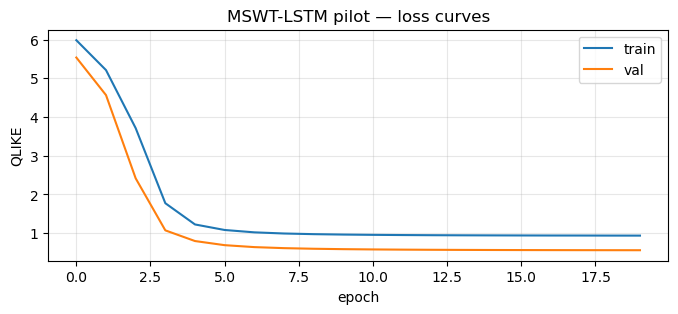

In [5]:
import matplotlib.pyplot as plt

hist = model.get_history()
plt.figure(figsize=(8, 3))
plt.plot(hist["train_loss"], label="train")
plt.plot(hist["val_loss"],   label="val")
plt.xlabel("epoch"); plt.ylabel("QLIKE"); plt.legend(); plt.grid(alpha=0.3)
plt.title("MSWT-LSTM pilot — loss curves")
plt.show()

In [2]:
# Sanity check: LSTM must be identical to what it was before (no change).
# No code change was made to LSTM, so this is trivially true.
import inspect
from src.models.dl_base import BasePyTorchVolatilityModel
src = inspect.getsource(BasePyTorchVolatilityModel)
assert "_build_dataset" not in src, "dl_base.py was modified!"
assert "_build_input" not in src, "dl_base.py was modified!"
print("OK: dl_base.py is untouched.")

# Sanity check: MSWT runs end-to-end with retrain_freq=1.
model = MSWT_LSTMModel(
    look_back=28, hidden_size=32, num_layers=1, dropout=0.1,
    J=2, wavelet="db4", gating_dim=16, gating_hidden_layers=2,
    learning_rate=1e-3, weight_decay=1e-6,
    max_epochs=10, patience=5, batch_size=128,
    retrain_freq=1, fine_tune_epochs=3, target_scale=1e4,
)
model.fit(y_train[:500], rs_train[:500])
preds = model.forecast(y_test[:10], rs_test[:10])
print("OK: MSWT runs with retrain_freq=1. preds:", preds[:3])

OK: dl_base.py is untouched.
OK: MSWT runs with retrain_freq=1. preds: [8.63867044e-05 9.65127051e-05 1.17761767e-04]


In [7]:
import os
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

In [11]:
import os
import time
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

FULL_DIR = RESULTS_PATH / "quick_test_J2"
FULL_DIR.mkdir(parents=True, exist_ok=True)

# Recorte para prueba rápida
y_small = y_train[:1000]
rs_small = rs_train[:1000]


def mswt_search_space_quick(trial: optuna.Trial) -> dict:
    return {
        "look_back": 28,           # <-- CAMBIO: mínimo para J=2 con db4
        "wavelet": "db4",
        "J": 2,                    # <-- CAMBIO: probamos descomposición de 3 bandas
        "hidden_size": 16,
        "num_layers": 1,
        "gating_dim": 16,
        "gating_hidden_layers": 2,
        "dropout": 0.1,
        "learning_rate": 1e-3,
        "weight_decay": 1e-6,
        "max_epochs": 100,          # 10 épocas para que vuele
        "patience": 10,
        "retrain_freq": 1,         # Fine-tuning diario
        "target_scale": 1e4,
        "seed": 42,
    }


print("Iniciando MSWT-LSTM | PRUEBA RÁPIDA (J=2)")

trainer = WalkForwardTrainer(
    model_class=MSWT_LSTMModel,
    scorer=VolatilityScorer(),
    output_dir=FULL_DIR,
    n_splits=2,                    # 1 solo fold
    warmup=800,                    # 800 train, 200 test
    embargo=1,
    suggest_params_fn=mswt_search_space_quick,
    n_trials=5,                    # 1 solo trial
    early_stop_rounds=None,
)

t0 = time.time()
trainer.run(y_small, rs_small)
print(f"Tiempo total: {(time.time() - t0) / 60:.2f} min")

Iniciando MSWT-LSTM | PRUEBA RÁPIDA (J=2)


  0%|          | 0/5 [00:00<?, ?it/s]

Tiempo total: 15.00 min


In [13]:
csv_path

WindowsPath('C:/Users/jcami/Documents/brent-crude-nlp-market-dynamics/results/MSWT_LSTM/quick_test2/MSWT_LSTMModel_results.csv')

In [17]:
import pandas as pd

# La ruta exacta donde se guardó el CSV
csv_path = RESULTS_PATH / "quick_test_J2" / "MSWT_LSTMModel_results.csv"

df_results = pd.read_csv(csv_path)
display(df_results)

,look_back,wavelet,J,hidden_size,num_layers,gating_dim,gating_hidden_layers,dropout,learning_rate,weight_decay,...,retrain_freq,target_scale,seed,fold,train_size,val_size,converged,epochs_run,train_time_sec,qlike
0,28,db4,2,16,1,16,2,0.1,0.001,0.000001,...,1,10000.0,42,1,799,100,False,100,15.56,0.329286
1,28,db4,2,16,1,16,2,0.1,0.001,0.000001,...,1,10000.0,42,2,899,100,True,30,5.71,0.512147


In [16]:
import pandas as pd

# La ruta exacta donde se guardó el CSV
csv_path = RESULTS_PATH / "quick_test" / "MSWT_LSTMModel_results.csv"

# Leer y mostrar
df_results = pd.read_csv(csv_path)
display(df_results)

,look_back,wavelet,J,hidden_size,num_layers,gating_dim,gating_hidden_layers,dropout,learning_rate,weight_decay,...,retrain_freq,target_scale,seed,fold,train_size,val_size,converged,epochs_run,train_time_sec,qlike
0,14,db4,1,16,1,16,2,0.1,0.001,0.000001,...,5,10000.0,42,1,799,200,False,5,0.61,0.435642


# ESTA ES LA CORRIDA COMPLETA

In [ ]:
import os
import time
import optuna

os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true" 

from src.models.original_model import MSWT_LSTMModel, min_window_length
from src.eval.scorer import VolatilityScorer
from src.trainer.walk_forward import WalkForwardTrainer

FULL_DIR = RESULTS_PATH / "mswt_lstm_full_run"
FULL_DIR.mkdir(parents=True, exist_ok=True)

def mswt_search_space(trial: optuna.Trial) -> dict:
    wavelet = "db4"
    look_back = trial.suggest_categorical("look_back", [14, 28, 56])

    max_J = 0
    for j in range(1, 6):
        if look_back >= min_window_length(wavelet, j):
            max_J = j
    J = trial.suggest_int("J", 1, max_J)

    return {
        "look_back": look_back,
        "wavelet": wavelet,
        "J": J,
        "hidden_size": trial.suggest_categorical("hidden_size", [32, 64, 128]),
        "num_layers": trial.suggest_int("num_layers", 1, 2),
        "gating_dim": trial.suggest_categorical("gating_dim", [32, 64, 128]),
        "gating_hidden_layers": trial.suggest_int("gating_hidden_layers", 2, 3),
        "dropout": trial.suggest_float("dropout", 0.0, 0.3),
        "learning_rate": trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        "max_epochs": 200,          
        "patience": 20,             
        "retrain_freq": 1,         
        "target_scale": 1e4,
        "seed": 42,
    }

current_warmup = 1210
print(f"Iniciando MSWT-LSTM | Ejecución Única | warmup={current_warmup}")

trainer = WalkForwardTrainer(
    model_class=MSWT_LSTMModel,      
    scorer=VolatilityScorer(),
    output_dir=FULL_DIR,
    n_splits=5,
    warmup=current_warmup,
    embargo=1,
    suggest_params_fn=mswt_search_space,
    n_trials=50,               
    early_stop_rounds=15,       
)

t0 = time.time()
trainer.run(y_train, rs_train)
print(f"Tiempo total: {(time.time() - t0) / 60:.1f} min")